> **Long run.** Same notebook with numbers of replicas, toy experiments and chain lengths close to those of the report.

# 06 · Bayesian analysis (2/3): systematic uncertainty, coverage and model checks

**What this notebook does.** The same 13 variants and combination rule as in the frequentist study, now with Bayesian
fits; toy experiments for the coverage of the credible interval; the posterior predictive check [EXTRA]; magnet
polarities with the sequential update; the Dalitz region and the $D^0$ veto; and the comparison of the posterior with
the profile likelihood.

| § | Content | Report section |
|---|---|---|
| 5 | Thirteen Bayesian variants, prior check | Result and systematic uncertainties |
| 6 | Toy experiments: coverage of the credible interval | Validation (add.: toy-MC coverage) |
| 7 | Posterior predictive check, also with statistics not fitted [EXTRA] | Model adequacy |
| 8 | Polarities, sequential update, Dalitz region, $D^0$ veto | Robustness checks |
| 9 | Comparison with the profile likelihood and the regions in $(A,A_b)$ | Discussion |

**Scale.** A guided tour of the method, not the production run: replicas, toy experiments and chains are fewer than in
the report, so numbers can differ slightly from it; next to every result the notebook prints the value of the report
(**report:**). The notebook is self-contained and saves its figures in `figures/` and its numbers in `results/`.
Parts beyond the techniques of the course are tagged **[EXTRA]**.

## 0 · Common setup (data, model and a posterior sample, as in notebook 05)

## 0 · Setup

In [1]:
import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot, emcee, corner
from scipy.special import ndtr
from scipy.stats import norm, chi2, crystalball, gaussian_kde
from iminuit import Minuit

import plot_style
plot_style.use()
C = plot_style.COLORS
T0 = time.time()
np.random.seed(42)

# figures and numerical results are saved next to the notebook
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
def save_fig(name):
    """Save the current figure in figures/ and show it."""
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

DATA_DIR = "data" if os.path.isdir("data") else "../../opendata-project/Data"
M_K = 493.677
LO, HI = 5100.0, 5600.0

## 1 · Data, prior, likelihood and posterior

### 1.1 Data
Same preselection and window as in notebook 01 (all three tracks kaon-like and not muons), here in compact form.
We keep the candidates with the weaker PID cut of the variants ($\texttt{ProbK}>0.4$, $\texttt{ProbPi}<0.6$) and
store the weakest PID value of each candidate, so that variants only re-apply tighter cuts.

In [2]:
tracks = (1, 2, 3)                          # the three final-state hadrons
branches = [f"H{i}_{v}" for i in tracks for v in ("PX", "PY", "PZ", "ProbK", "ProbPi", "isMuon", "Charge")]
frames = []
for pol in ("Down", "Up"):                  # one file per magnet polarity
    with uproot.open(f"{DATA_DIR}/B2HHH_Magnet{pol}.root") as f:
        t = f["DecayTree"].arrays(branches, library="pd")
    t["magnet"] = pol.lower()
    frames.append(t)
df = pd.concat(frames, ignore_index=True)

# loose preselection (looser than every variant of the systematic study): kaon-like and not muon on all three tracks
keep = np.ones(len(df), bool)
for i in tracks:
    keep &= ((df[f"H{i}_ProbK"] > 0.4) & (df[f"H{i}_ProbPi"] < 0.6) & ~df[f"H{i}_isMuon"].astype(bool)).to_numpy()
d = df[keep].reset_index(drop=True); del df

def invariant_mass(d, particles):
    """Invariant mass [MeV] of the listed tracks with the kaon-mass hypothesis: m^2 = E^2 - |p|^2."""
    E = sum(np.sqrt(d[f"H{i}_PX"]**2 + d[f"H{i}_PY"]**2 + d[f"H{i}_PZ"]**2 + M_K**2) for i in particles)
    px, py, pz = (sum(d[f"H{i}_{c}"] for i in particles) for c in ("PX", "PY", "PZ"))
    return np.sqrt(np.clip(E**2 - px**2 - py**2 - pz**2, 0, None))

d["m"], d["m12"], d["m13"] = invariant_mass(d, (1, 2, 3)), invariant_mass(d, (1, 2)), invariant_mass(d, (1, 3))
d["q"] = d.H1_Charge + d.H2_Charge + d.H3_Charge                      # charge of the B
d["min_probk"] = d[[f"H{i}_ProbK" for i in tracks]].min(axis=1)       # weakest kaon likelihood of the candidate
d["max_probpi"] = d[[f"H{i}_ProbPi" for i in tracks]].max(axis=1)     # largest pion likelihood of the candidate
d = d[np.abs(d.q) == 1]

def select(lo=LO, hi=HI, k=0.5, pi=0.5, s=None):
    """Candidates with mass in (lo, hi), min ProbK > k and max ProbPi < pi (nominal: 0.5, 0.5)."""
    s = d if s is None else s
    return s[(s.m > lo) & (s.m < hi) & (s.min_probk > k) & (s.max_probpi < pi)].reset_index(drop=True)

sample = select()                                                     # nominal sample
m_pos, m_neg = sample.m[sample.q > 0].to_numpy(), sample.m[sample.q < 0].to_numpy()
print(f"candidates in the window: {len(sample)} (report 19731);  B+: {len(m_pos)}, B-: {len(m_neg)}")

candidates in the window: 19731 (report 19731);  B+: 10292, B-: 9439


### 1.2 The model, written as log-prior, log-likelihood and log-posterior

The model is that of notebook 01: for each charge a Gaussian signal (mean $\mu$ and width $\sigma$ shared) and a
double-exponential background (own shape and yield), $N_s^\pm=\frac{N_s}{2}(1\mp A)$,
$N_b^\pm=\frac{N_b}{2}(1\mp A_b)$. Twelve parameters
$\theta=(N_s,N_b,A,A_b,\mu,\sigma,\lambda_1^\pm,\lambda_2^\pm,f_\pm)$.

* **Prior** $\pi(\theta)$: independent and **uniform** on the ranges below (constant in the allowed region, zero
  outside); $\lambda_1>\lambda_2$ removes the label-switching symmetry of the two exponentials. With flat priors the
  posterior is proportional to the likelihood inside the allowed region.
* **Likelihood**: the extended unbinned likelihood of notebook 01.
* **Posterior**: $\ln p(\theta|D)=\ln\mathcal L(D|\theta)+\ln\pi(\theta)$ + const. The evidence $p(D)$ is a constant
  that the MCMC does not need.

In [3]:
# the 12 parameters, in the order of the vector theta used by the sampler
names = ["N_s", "N_b", "A", "A_b", "mu", "sigma", "lam1_pos", "lam2_pos", "f_pos", "lam1_neg", "lam2_neg", "f_neg"]
N = len(sample)
# uniform prior = allowed range of each parameter (zero probability outside)
PRIOR = {"N_s": (0, 5 * N), "N_b": (0, 5 * N), "A": (-1, 1), "A_b": (-1, 1), "mu": (5260, 5310), "sigma": (3, 40),
         "lam1_pos": (1e-5, 0.1), "lam2_pos": (1e-5, 0.1), "f_pos": (0, 1),
         "lam1_neg": (1e-5, 0.1), "lam2_neg": (1e-5, 0.1), "f_neg": (0, 1)}

# building blocks of the model, as in notebook 01
def gauss_pdf(m, mu, sigma, lo=LO, hi=HI):
    """Gaussian normalised on [lo, hi]: written with ndtr (the normal cdf) because it is faster than scipy.stats."""
    z = (m - mu) / sigma
    return np.exp(-0.5 * z * z) / (sigma * np.sqrt(2 * np.pi)) / (ndtr((hi - mu) / sigma) - ndtr((lo - mu) / sigma))

def exp_pdf(m, lam, lo=LO, hi=HI):
    """Exponential exp(-lam (m - lo)) normalised on [lo, hi]."""
    return lam * np.exp(-lam * (m - lo)) / (1 - np.exp(-lam * (hi - lo)))

def bkg_pdf(m, lam1, lam2, f, lo=LO, hi=HI):
    """Background: weight f on the steep exponential (lam1 > lam2), 1 - f on the slow one."""
    return f * exp_pdf(m, lam1, lo, hi) + (1 - f) * exp_pdf(m, lam2, lo, hi)

def log_prior(theta):
    """ln of the prior: 0 inside the allowed region (uniform, an irrelevant constant), -inf outside."""
    v = dict(zip(names, theta))
    for k in names:
        if not PRIOR[k][0] < v[k] < PRIOR[k][1]:
            return -np.inf
    if v["lam1_pos"] <= v["lam2_pos"] or v["lam1_neg"] <= v["lam2_neg"]:      # ordering of the two exponentials
        return -np.inf                                                       # (removes the label-switching symmetry)
    return 0.0

def log_likelihood(theta, m_p, m_n):
    """ln of the extended unbinned likelihood of the B+ masses m_p and B- masses m_n."""
    v = dict(zip(names, theta))
    Ns_p, Ns_n = v["N_s"] * (1 - v["A"]) / 2, v["N_s"] * (1 + v["A"]) / 2          # signal yields per charge
    Nb_p, Nb_n = v["N_b"] * (1 - v["A_b"]) / 2, v["N_b"] * (1 + v["A_b"]) / 2      # background yields per charge
    dens_p = Ns_p * gauss_pdf(m_p, v["mu"], v["sigma"]) + Nb_p * bkg_pdf(m_p, v["lam1_pos"], v["lam2_pos"], v["f_pos"])
    dens_n = Ns_n * gauss_pdf(m_n, v["mu"], v["sigma"]) + Nb_n * bkg_pdf(m_n, v["lam1_neg"], v["lam2_neg"], v["f_neg"])
    return np.sum(np.log(dens_p)) + np.sum(np.log(dens_n)) - (v["N_s"] + v["N_b"])    # extended: -(N_s + N_b)

def log_posterior(theta, m_p=m_pos, m_n=m_neg):
    """ln posterior = ln prior + ln likelihood (up to a constant: the evidence)."""
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    ll = log_likelihood(theta, m_p, m_n)
    return lp + ll if np.isfinite(ll) else -np.inf

### 1.3 Starting point: the maximum of the posterior

With flat priors the maximum of the posterior (MAP) is the maximum-likelihood estimate: we find it with `Migrad`
and use it to start the walkers close to the bulk.

In [4]:
# rough starting values
theta0 = dict(N_s=0.78 * N, N_b=0.22 * N, A=-0.04, A_b=0.0, mu=5284.0, sigma=18.0,
              lam1_pos=0.03, lam2_pos=0.002, f_pos=0.15, lam1_neg=0.03, lam2_neg=0.002, f_neg=0.15)

def neg2logp(*theta):
    """-2 ln posterior, the function that Migrad minimises (a large number outside the prior)."""
    lp = log_posterior(np.array(theta))
    return -2 * lp if np.isfinite(lp) else 1e10

mmap = Minuit(neg2logp, *[theta0[k] for k in names], name=names)
for k in names:
    mmap.limits[k] = PRIOR[k]               # the prior ranges are the limits of the minimisation
mmap.migrad()
theta_map = np.array(mmap.values)           # maximum of the posterior (= maximum likelihood with flat priors)
print(f"MAP: A = {mmap.values['A']:+.4f},  N_s = {mmap.values['N_s']:.0f},  mu = {mmap.values['mu']:.2f},  "
      f"sigma = {mmap.values['sigma']:.2f}   (valid: {mmap.valid})")
# cost of one evaluation: sets the cost of the MCMC (walkers x steps evaluations)
t0 = time.time(); [log_posterior(theta_map) for _ in range(200)]
print(f"time per log-posterior call: {(time.time() - t0) / 200 * 1e3:.2f} ms")

MAP: A = -0.0441,  N_s = 15328,  mu = 5284.38,  sigma = 18.00   (valid: True)
time per log-posterior call: 0.72 ms


In [5]:
# Posterior of the nominal model: a shorter chain than in notebook 05 (which has the long one and its diagnostics)
NWALKERS, NSTEPS, BURN = 32, 25000, 5000
ndim = len(names)
p0 = theta_map + 1e-3 * np.abs(theta_map) * np.random.randn(NWALKERS, ndim)
for k in ("A", "A_b"):
    p0[:, names.index(k)] = theta_map[names.index(k)] + 1e-3 * np.random.randn(NWALKERS)
sampler = emcee.EnsembleSampler(NWALKERS, ndim, log_posterior)
sampler.run_mcmc(p0, NSTEPS, progress=False)
chain = sampler.get_chain(discard=BURN, flat=True)
A_s, Ab_s = chain[:, names.index("A")], chain[:, names.index("A_b")]
print(f"nominal posterior: A = {np.median(A_s):+.4f} +- {A_s.std():.4f}  (long chain in notebook 05)")

nominal posterior: A = -0.0442 +- 0.0085  (long chain in notebook 05)


**Reading the result.** An acceptance fraction of $0.3$–$0.4$ is typical of a healthy ensemble sampler. The integrated autocorrelation time $\tau$ is the number of steps after which samples are effectively independent; a chain longer than about $50\,\tau$ gives a reliable estimate of the posterior (the report uses a longer chain).

## 5 · Systematic uncertainty: the same 13 variants, Bayesian fits

The variants and the combination rule are those of notebook 03 (window, background, signal, preselection; Barlow
criterion $\sigma_B$ for the variants that change the sample [EXTRA], rejection of variants that the data reject,
largest shift of each group, groups in quadrature). Each variant is a new MCMC fit. A variant is the nominal model
with some parameters **tied** (e.g. the background shape of $B^-$ equal to that of $B^+$), **fixed** ($A_b=0$) or
**added** (the tail of the Crystal Ball), or with a different window: it is described by the list of the parameters
that are sampled and by a short function that completes the others, written out explicitly below.

In [6]:
from scipy.stats import crystalball

def cb_pdf(m, mu, sigma, beta, m_cb, lo=LO, hi=HI):
    """Crystal Ball (Gaussian core with a power-law low-mass tail) normalised on [lo, hi]."""
    z = crystalball.cdf((hi - mu) / sigma, beta, m_cb) - crystalball.cdf((lo - mu) / sigma, beta, m_cb)
    return crystalball.pdf((m - mu) / sigma, beta, m_cb) / sigma / z

def density(v, side, m, lo=LO, hi=HI, cb=False):
    """Expected density of the events of one charge. v is a dictionary with ALL the parameters of the model."""
    sign = -1 if side == "pos" else +1
    n_sig = v["N_s"] * (1 + sign * v["A"]) / 2
    n_bkg = v["N_b"] * (1 + sign * v["A_b"]) / 2
    mu = v.get(f"mu_{side}", v.get("mu"))                  # mu and sigma: own for each charge, or common
    sigma = v.get(f"sigma_{side}", v.get("sigma"))
    sig = cb_pdf(m, mu, sigma, v["beta"], v["m_cb"], lo, hi) if cb else gauss_pdf(m, mu, sigma, lo, hi)
    bkg = bkg_pdf(m, v[f"lam1_{side}"], v[f"lam2_{side}"], v[f"f_{side}"], lo, hi)
    return n_sig * sig + n_bkg * bkg

# the functions that complete the dictionary of a variant with its tied or fixed parameters
def nothing(v):
    pass
def tie_shapes(v):              # background shape of B- equal to that of B+
    v["lam1_neg"], v["lam2_neg"], v["f_neg"] = v["lam1_pos"], v["lam2_pos"], v["f_pos"]
def zero_Ab(v):                 # charge-symmetric background
    v["A_b"] = 0.0
def one_exponential(v):         # a single exponential: all the weight on the first one
    v["f_pos"] = v["f_neg"] = 1.0
    v["lam2_pos"] = v["lam2_neg"] = 1e-4

def without(all_names, drop):
    return [n for n in all_names if n not in drop]

# a variant = names of the SAMPLED parameters + function that completes the others + window + signal shape
NOM = dict(names=names, fill=nothing, lo=LO, hi=HI, cb=False, start={})          # the nominal model of section 1

def make_prior(n_cand, a_bound=1.0):
    """Uniform priors: allowed range of every parameter that any variant can have."""
    return {"N_s": (0, 5 * n_cand), "N_b": (0, 5 * n_cand), "A": (-a_bound, a_bound), "A_b": (-1, 1),
            "mu": (5260, 5310), "sigma": (3, 40), "mu_pos": (5260, 5310), "mu_neg": (5260, 5310),
            "sigma_pos": (3, 40), "sigma_neg": (3, 40), "beta": (0.3, 5), "m_cb": (1.01, 50),
            "lam1_pos": (1e-5, 0.1), "lam2_pos": (1e-5, 0.1), "f_pos": (0, 1),
            "lam1_neg": (1e-5, 0.1), "lam2_neg": (1e-5, 0.1), "f_neg": (0, 1)}

def log_posterior_variant(theta, spec, prior, m_p, m_n):
    """ln posterior of a variant (uniform priors, extended likelihood), at the vector theta of its sampled parameters."""
    v = dict(zip(spec["names"], theta))
    for k in spec["names"]:                                # uniform prior: inside the allowed range or zero
        if not prior[k][0] < v[k] < prior[k][1]:
            return -np.inf
    spec["fill"](v)                                        # tied and fixed parameters
    if "lam2_pos" in spec["names"] and (v["lam1_pos"] <= v["lam2_pos"] or v["lam1_neg"] <= v["lam2_neg"]):
        return -np.inf                                     # ordering of the two exponentials
    dp = density(v, "pos", m_p, spec["lo"], spec["hi"], spec["cb"])
    dn = density(v, "neg", m_n, spec["lo"], spec["hi"], spec["cb"])
    if np.any(dp <= 0) or np.any(dn <= 0):
        return -np.inf
    return np.sum(np.log(dp)) + np.sum(np.log(dn)) - (v["N_s"] + v["N_b"])      # extended likelihood

# check: the nominal variant is exactly the posterior of section 1
assert abs(log_posterior_variant(theta_map, NOM, make_prior(len(sample)), m_pos, m_neg) - log_posterior(theta_map)) < 1e-6
print("nominal variant = posterior of section 1: OK")

nominal variant = posterior of section 1: OK


In [7]:
def fit_map(s, spec=NOM, a_bound=1.0, start_from=None):
    """Maximum of the posterior of a variant (Migrad). Returns the Minuit object and the log-posterior function."""
    mp, mn = s.m[s.q > 0].to_numpy(), s.m[s.q < 0].to_numpy()
    prior = make_prior(len(s), a_bound)
    lp = lambda theta: log_posterior_variant(theta, spec, prior, mp, mn)
    start = {"N_s": 0.78 * len(s), "N_b": 0.22 * len(s), "A": -0.04, "A_b": 0.0, "mu": 5284.0, "sigma": 18.0,
             "mu_pos": 5284.0, "mu_neg": 5284.0, "sigma_pos": 18.0, "sigma_neg": 18.0, "beta": 1.8, "m_cb": 10.0,
             "lam1_pos": 0.03, "lam1_neg": 0.03, "lam2_pos": 0.002, "lam2_neg": 0.002, "f_pos": 0.15, "f_neg": 0.15}
    start.update(spec["start"]); start.update(start_from or {})
    def f(*theta):                                         # -2 ln posterior for Migrad
        v = lp(np.array(theta))
        return -2 * v if np.isfinite(v) else 1e10
    mm = Minuit(f, *[start[k] for k in spec["names"]], name=spec["names"])
    for k in spec["names"]:
        mm.limits[k] = prior[k]
    mm.migrad()
    return mm, lp

def bayes_fit(s, spec=NOM, nsteps=10000, burn=2000, nwalkers=None, a_bound=1.0, start_from=None):
    """Posterior of a variant: maximum of the posterior (start of the walkers), then emcee.
    s is a DataFrame with columns m and q; spec describes the variant."""
    mm, lp = fit_map(s, spec, a_bound, start_from)
    nm = spec["names"]
    x_map = np.array(mm.values)
    nw = nwalkers or max(2 * len(nm) + 2, 24)                 # emcee needs at least 2 x parameters walkers
    p0 = x_map + 1e-3 * np.abs(x_map) * np.random.randn(nw, len(nm))      # small ball around the maximum
    for k in ("A", "A_b"):                                    # A, A_b are close to zero: absolute spread
        if k in nm: p0[:, nm.index(k)] = x_map[nm.index(k)] + 1e-3 * np.random.randn(nw)
    for w in range(nw):                                       # every walker must start inside the prior
        while not np.isfinite(lp(p0[w])):
            p0[w] = x_map + 1e-4 * np.abs(x_map) * np.random.randn(len(nm))
    samp = emcee.EnsembleSampler(nw, len(nm), lp)
    samp.run_mcmc(p0, nsteps, progress=False)
    ch = samp.get_chain(discard=burn, flat=True)              # drop the burn-in, merge the walkers

    def expected(v, side, m):                                 # expected density at the parameters v (a dictionary)
        full = dict(v); spec["fill"](full)
        return density(full, side, m, spec["lo"], spec["hi"], spec["cb"])
    return dict(names=nm, chain=ch, map=x_map, logpost=lp, density=expected, minuit=mm,
                A=np.median(ch[:, nm.index("A")]), sd=ch[:, nm.index("A")].std(),
                ci68=np.percentile(ch[:, nm.index("A")], [15.865, 84.135]), n=len(s))

def binned_chi2_bayes(res, s, lo=LO, hi=HI, width=10.0):
    """Pearson chi2 (10 MeV bins, both charges) at the posterior median of the parameters."""
    v = dict(zip(res["names"], np.median(res["chain"], axis=0)))
    edges = np.arange(lo, hi + 1e-9, width)
    sub = (np.arange(5) + 0.5) / 5                            # 5 points per bin to average the density
    pts = edges[:-1, None] + sub[None, :] * width
    chi2_ = 0.0
    for side, mask in (("pos", s.q > 0), ("neg", s.q < 0)):
        nu = res["density"](v, side, pts).mean(axis=1) * width          # expected counts per bin
        obs = np.histogram(s.m[mask], edges)[0]                         # observed counts per bin
        chi2_ += np.sum((obs - nu)**2 / nu)
    return chi2_

In [8]:
# the 13 variants, as in notebook 03: name -> (group, change of the SAMPLE, description of the model)
VARIANTS = {
    "window_lo5050":       ("window", dict(lo=5050.0), {**NOM, "lo": 5050.0}),
    "window_lo5150":       ("window", dict(lo=5150.0), {**NOM, "lo": 5150.0}),
    "window_hi5450":       ("window", dict(hi=5450.0), {**NOM, "hi": 5450.0}),
    "window_hi5700":       ("window", dict(hi=5700.0), {**NOM, "hi": 5700.0}),
    # background: one exponential / same shape for the two charges / A_b = 0
    "bkg_single_exp":      ("background", {}, {**NOM, "names": without(names, ["lam2_pos", "f_pos", "lam2_neg", "f_neg"]),
                                               "fill": one_exponential, "start": {"lam1_pos": 0.004, "lam1_neg": 0.004}}),
    "bkg_shared_shape":    ("background", {}, {**NOM, "names": without(names, ["lam1_neg", "lam2_neg", "f_neg"]), "fill": tie_shapes}),
    "bkg_symmetric":       ("background", {}, {**NOM, "names": without(names, ["A_b"]), "fill": zero_Ab}),
    # signal: Crystal Ball / mu and sigma of each charge
    "signal_crystal_ball": ("signal", {}, {**NOM, "names": names + ["beta", "m_cb"], "cb": True}),
    "signal_per_charge":   ("signal", {}, {**NOM, "names": without(names, ["mu", "sigma"]) + ["mu_pos", "sigma_pos", "mu_neg", "sigma_neg"]}),
    # preselection: the model is the nominal one, the sample changes
    "presel_probk_0.4":    ("preselection", dict(k=0.4), NOM),
    "presel_probk_0.6":    ("preselection", dict(k=0.6), NOM),
    "presel_probpi_0.4":   ("preselection", dict(pi=0.4), NOM),
    "presel_probpi_0.6":   ("preselection", dict(pi=0.6), NOM),
}
# values of the report, printed next to ours
REPORT_A = {"window_lo5050": -0.0446, "window_lo5150": -0.0444, "window_hi5450": -0.0440, "window_hi5700": -0.0456,
            "bkg_single_exp": -0.0480, "bkg_shared_shape": -0.0480, "bkg_symmetric": -0.0471,
            "signal_crystal_ball": -0.0445, "signal_per_charge": -0.0443,
            "presel_probk_0.4": -0.0474, "presel_probk_0.6": -0.0385, "presel_probpi_0.4": -0.0421, "presel_probpi_0.6": -0.0446}
SAMPLE_CHANGING = ("window", "preselection")        # variants fitted on a different (nested) sample: sigma_B applies

t0 = time.time()
nominal = dict(A=np.median(A_s), sd=A_s.std())      # nominal posterior: median and standard deviation of A

def nominal_density(v, side, m):
    """Expected density of the nominal model for one charge (needed for the chi2 of the nominal fit)."""
    sign = -1 if side == "pos" else +1
    return ((v["N_s"] * (1 + sign * v["A"]) / 2) * gauss_pdf(m, v["mu"], v["sigma"])
            + (v["N_b"] * (1 + sign * v["A_b"]) / 2) * bkg_pdf(m, v[f"lam1_{side}"], v[f"lam2_{side}"], v[f"f_{side}"]))
chi2_nom = binned_chi2_bayes(dict(names=names, chain=chain, density=nominal_density), sample)

rows = []
for name, (group, sel_opt, spec) in VARIANTS.items():
    s = select(**sel_opt)                           # sample of the variant
    r = bayes_fit(s, spec)                          # Bayesian fit of the model of the variant
    changes = group in SAMPLE_CHANGING
    shift = r["A"] - nominal["A"]                   # shift of the posterior median
    # statistical fluctuation expected between nested samples (Barlow criterion)
    sigma_B = np.sqrt(abs(r["sd"]**2 - nominal["sd"]**2)) if changes else np.nan
    c2 = binned_chi2_bayes(r, s, spec["lo"], spec["hi"])                # chi2 in the window of this variant
    n_bins = int(round((spec["hi"] - spec["lo"]) / 10))
    rejected = (not changes) and (c2 - chi2_nom > 25)                  # a variant that the data reject is excluded
    counts = (not rejected) and ((not changes) or abs(shift) > sigma_B)
    rows.append(dict(variant=name, group=group, n=len(s), A=r["A"], shift=shift, sigma_B=sigma_B,
                     rejected=rejected, counts=counts, chi2=c2, ndof=2 * n_bins - len(r["names"]), report_A=REPORT_A[name]))
syst = pd.DataFrame(rows)
print(f"13 Bayesian fits in {time.time() - t0:.0f} s")
print(syst.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))
# group uncertainty = largest contributing shift; independent groups added in quadrature
group_unc = syst[syst.counts].groupby("group")["shift"].apply(lambda x: x.abs().max())
group_unc = group_unc.reindex(["window", "background", "signal", "preselection"]).fillna(0.0)
syst_total = np.sqrt((group_unc**2).sum())
print("\nuncertainty by group:", group_unc.round(4).to_dict())
print(f"total systematic = {syst_total:.4f}   (report: 0.0014, 0.0037, 0.0002, 0.0058 -> 0.0070)")
print("\nnote: with 1500 steps the posterior median of each variant has a Monte-Carlo error of ~0.0005, comparable to the")
print("shifts of the window variants and to sigma_B: variants close to the threshold can be classified differently from the report")
print(f"\nResult: A_raw = {nominal['A']:+.4f} +- {nominal['sd']:.4f} (stat) +- {syst_total:.4f} (syst)   report: -0.0443 +- 0.0085 +- 0.0070")

13 Bayesian fits in 1494 s
            variant        group     n       A   shift  sigma_B  rejected  counts      chi2  ndof  report_A
      window_lo5050       window 21164 -0.0448 -0.0005  +0.0001     False    True +212.9809    98   -0.0446
      window_lo5150       window 18566 -0.0440 +0.0002  +0.0015     False   False +136.7809    78   -0.0444
      window_hi5450       window 19004 -0.0445 -0.0002  +0.0008     False   False +132.4428    58   -0.0440
      window_hi5700       window 20191 -0.0452 -0.0010  +0.0002     False    True +195.5231   108   -0.0456
     bkg_single_exp   background 19731 -0.0483 -0.0041      NaN      True   False +294.0183    92   -0.0480
   bkg_shared_shape   background 19731 -0.0482 -0.0040      NaN     False    True +169.5193    91   -0.0480
      bkg_symmetric   background 19731 -0.0472 -0.0030      NaN     False    True +165.3295    89   -0.0471
signal_crystal_ball       signal 19731 -0.0450 -0.0007      NaN     False    True +126.2752    86   -0.0445
 

**Reading the result.** The shifts agree variant by variant with the frequentist ones (notebook 03) and the preselection dominates. With short chains the shifts of the variants close to the $\sigma_B$ threshold have a Monte-Carlo error of the same size as the shift, so their classification can differ from the report.

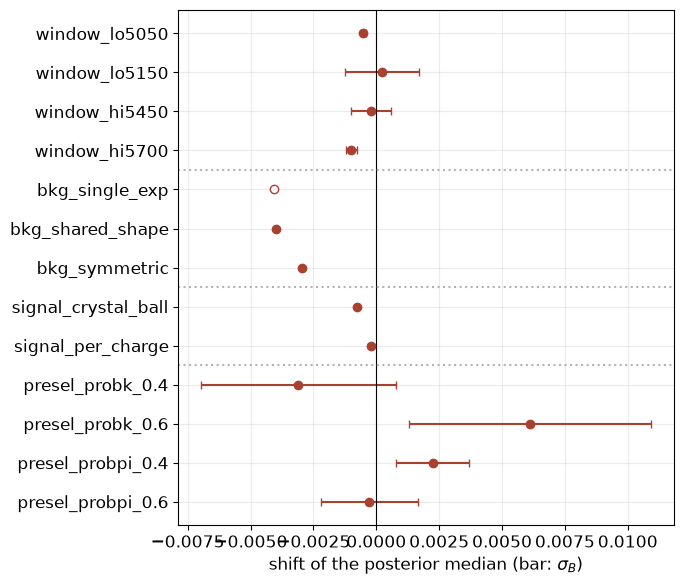

In [9]:
# shifts of the 13 Bayesian variants with sigma_B (open marker: rejected by the data)
fig, ax = plt.subplots(figsize=(7, 6))
yy = np.arange(len(syst))[::-1]
for y_, (_, r) in zip(yy, syst.iterrows()):
    ax.errorbar(r["shift"], y_, xerr=None if np.isnan(r.sigma_B) else r.sigma_B, fmt="o", color=C["bayes"], capsize=3,
                mfc="none" if r.rejected else C["bayes"])
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(yy); ax.set_yticklabels(syst.variant)
for sep in (3.5, 6.5, 8.5):
    ax.axhline(len(syst) - 1 - sep, color="0.7", ls=":")
ax.set(xlabel="shift of the posterior median (bar: $\\sigma_B$)")
plt.tight_layout(); save_fig("06_variant_shifts")

**Prior check.** The posterior of $A$ should not depend on the prior width: we refit with $A$ uniform on $(-0.3,0.3)$
instead of $(-1,1)$ (only the Bayes factor changes, §4). This is a check, not part of the systematic uncertainty.

In [10]:
r_nar = bayes_fit(sample, NOM, a_bound=0.3)
print(f"A with the prior A in (-0.3, 0.3): {r_nar['A']:+.4f} (nominal {nominal['A']:+.4f}, shift {r_nar['A'] - nominal['A']:+.4f})"
      "   (report: no change)")

A with the prior A in (-0.3, 0.3): -0.0447 (nominal -0.0442, shift -0.0004)   (report: no change)


## 6 · Toy experiments: does the 68 % credible interval contain the truth 68 % of the time?

A credible interval is a statement about $A$ given the data and the prior; it need not have frequentist coverage.
With a large sample and flat priors it should (Bernstein–von Mises). We **generate pseudo-experiments from the model**
at the posterior medians (Poisson yields, masses by the transformation method, as in notebook 02), fit each with the
same posterior and count how often the 68 % and 95 % credible intervals contain the injected $A$. The pulls
$(\hat A-A_{\rm true})/\sigma(\hat A)$ must be standard normal.

*Report:* 200 toys, 12 000 steps each. Here 20 toys of 1000 steps, started at the true value (no burn-in needed).

In [11]:
# random numbers by the transformation method, x = F^-1(u) with u uniform (as in notebook 02)
def sample_gauss(mu, sigma, n):
    u = np.random.uniform(norm.cdf(LO, mu, sigma), norm.cdf(HI, mu, sigma), n)      # truncated Gaussian
    return mu + sigma * norm.ppf(u)

def sample_exp(lam, n):
    return LO - np.log(1 - np.random.uniform(size=n) * (1 - np.exp(-lam * (HI - LO)))) / lam

def make_toy(v):
    """One pseudo-experiment (m_pos, m_neg) from the parameter dictionary v (nominal model)."""
    out = []
    for side, sign in (("pos", -1), ("neg", +1)):
        n_s = np.random.poisson(v["N_s"] * (1 + sign * v["A"]) / 2)          # Poisson yields
        n_b = np.random.poisson(v["N_b"] * (1 + sign * v["A_b"]) / 2)
        steep = np.random.uniform(size=n_b) < v[f"f_{side}"]                  # steep or slow exponential?
        bkg = np.where(steep, sample_exp(v[f"lam1_{side}"], n_b), sample_exp(v[f"lam2_{side}"], n_b))
        out.append(np.concatenate([sample_gauss(v["mu"], v["sigma"], n_s), bkg]))
    return out

v_true = dict(zip(names, np.median(chain, axis=0)))      # "true" parameters: posterior medians
A_true = v_true["A"]
N_TOYS = 60
toy_rows = []
t0 = time.time()
for i in range(N_TOYS):
    mp_t, mn_t = make_toy(v_true)                         # a pseudo-experiment ...
    toy = pd.DataFrame({"m": np.concatenate([mp_t, mn_t]), "q": np.concatenate([np.ones(len(mp_t)), -np.ones(len(mn_t))])})
    r = bayes_fit(toy, nsteps=6000, burn=1000, start_from=v_true)       # ... its posterior (walkers start at the truth)
    lo68, hi68 = r["ci68"]; lo95, hi95 = np.percentile(r["chain"][:, r["names"].index("A")], [2.5, 97.5])
    toy_rows.append(dict(A=r["A"], sd=r["sd"], in68=lo68 < A_true < hi68, in95=lo95 < A_true < hi95))   # covered?
toys = pd.DataFrame(toy_rows)
pull = (toys.A - A_true) / toys.sd                        # pulls: should be N(0, 1)
print(f"{N_TOYS} toys in {time.time() - t0:.0f} s")
print(f"coverage 68%: {toys.in68.mean():.2f} +- {np.sqrt(0.68 * 0.32 / N_TOYS):.2f}   95%: {toys.in95.mean():.2f} +- {np.sqrt(0.95 * 0.05 / N_TOYS):.2f}"
      "      (report: 0.65 +- 0.03, 0.93 +- 0.02)")
print(f"pulls: mean {pull.mean():+.2f} +- {pull.std() / np.sqrt(N_TOYS):.2f}, width {pull.std():.2f}      (report: width 1.04);  "
      f"bias of the median: {toys.A.mean() - A_true:+.4f} +- {toys.A.std() / np.sqrt(N_TOYS):.4f}")
print("with 20 toys the statistical uncertainty of every number above is large: this is a demonstration of the method;")
print("the report (200 toys) has uncertainties of 0.03 on the coverage and finds no bias")

60 toys in 2864 s
coverage 68%: 0.65 +- 0.06   95%: 0.92 +- 0.03      (report: 0.65 +- 0.03, 0.93 +- 0.02)
pulls: mean +0.05 +- 0.15, width 1.15      (report: width 1.04);  bias of the median: +0.0004 +- 0.0013
with 20 toys the statistical uncertainty of every number above is large: this is a demonstration of the method;
the report (200 toys) has uncertainties of 0.03 on the coverage and finds no bias


**Reading the result.** The credible intervals contain the injected value with a frequency compatible with their level, and the pulls are close to $N(0,1)$: for this problem, with flat priors and $\sim2\times10^4$ events, the credible interval has the right frequentist coverage.

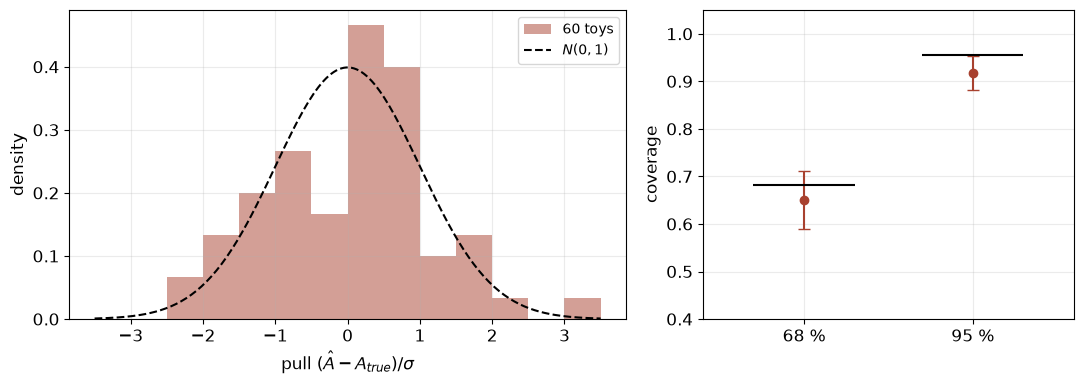

In [12]:
# pulls of the toy experiments and observed coverage against the nominal level
fig, ax = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.5, 1]})
ax[0].hist(pull, bins=np.linspace(-3.5, 3.5, 15), density=True, color=C["bayes"], alpha=0.5, label=f"{len(pull)} toys")
x = np.linspace(-3.5, 3.5, 200); ax[0].plot(x, norm.pdf(x), "k--", label="$N(0,1)$")
ax[0].set(xlabel="pull $(\\hat A-A_{true})/\\sigma$", ylabel="density"); ax[0].legend()
for x_, (cov_, nomv) in enumerate(((toys.in68.mean(), 0.6827), (toys.in95.mean(), 0.9545))):
    ax[1].errorbar([x_], [cov_], yerr=[np.sqrt(cov_ * (1 - cov_) / len(toys))], fmt="o", color=C["bayes"], capsize=4)
    ax[1].hlines(nomv, x_ - 0.3, x_ + 0.3, color="k")
ax[1].set(xticks=[0, 1], xticklabels=["68 %", "95 %"], ylabel="coverage", xlim=(-0.6, 1.6), ylim=(0.4, 1.05))
plt.tight_layout(); save_fig("06_toys_pulls_coverage")

## 7 · Does the model describe the data? Posterior predictive check [EXTRA]

The posterior says nothing about whether the *model* is adequate. The **posterior predictive check** simulates
replicas of the whole dataset from parameters drawn from the posterior and compares a discrepancy statistic computed
on the data with its distribution on the replicas; $p_B=P(T^{\rm rep}\ge T^{\rm obs})$.

We use the binned $\chi^2$ (which the fit indirectly optimises, so a weak test) and the counting asymmetry in the
fit window and in the sidebands $|m-\mu|>4\sigma$ (not fitted by the model).

In [13]:
# bins of 10 MeV and 5 sub-points per bin to average the model density
edges10 = np.arange(LO, HI + 1e-9, 10.0)
sub = (np.arange(5) + 0.5) / 5
pts10 = edges10[:-1, None] + sub[None, :] * 10.0

def chi2_binned(m_p, m_n, v):
    """Pearson chi2 of a dataset (m_p, m_n) against the model with parameters v (10 MeV bins, both charges)."""
    c = 0.0
    for side, mm in (("pos", m_p), ("neg", m_n)):
        sign = -1 if side == "pos" else +1
        dens = ((v["N_s"] * (1 + sign * v["A"]) / 2) * gauss_pdf(pts10, v["mu"], v["sigma"])
                + (v["N_b"] * (1 + sign * v["A_b"]) / 2) * bkg_pdf(pts10, v[f"lam1_{side}"], v[f"lam2_{side}"], v[f"f_{side}"]))
        nu = dens.mean(axis=1) * 10.0                         # expected counts per bin
        c += np.sum((np.histogram(mm, edges10)[0] - nu)**2 / nu)
    return c

def count_asym(m_p, m_n, sel=lambda m: np.ones_like(m, bool)):
    """Counting asymmetry of the candidates selected by `sel` (default: all)."""
    a, b = np.sum(sel(m_n)), np.sum(sel(m_p))
    return (a - b) / (a + b)

mu_hat, sg_hat = v_true["mu"], v_true["sigma"]
side_sel = lambda m: np.abs(m - mu_hat) > 4 * sg_hat      # sidebands: far from the peak
# posterior predictive check: for each posterior draw, compare the statistic on the data with that on a replica
T_obs, T_rep = [], []
for i in np.random.choice(len(chain), 1000, replace=False):
    v = dict(zip(names, chain[i]))                         # a draw from the posterior
    mp_r, mn_r = make_toy(v)                               # replica of the whole dataset from that draw
    T_obs.append([chi2_binned(m_pos, m_neg, v), count_asym(m_pos, m_neg), count_asym(m_pos, m_neg, side_sel)])
    T_rep.append([chi2_binned(mp_r, mn_r, v), count_asym(mp_r, mn_r), count_asym(mp_r, mn_r, side_sel)])
T_obs, T_rep = np.array(T_obs), np.array(T_rep)
for k, lab in enumerate(("chi2 (10 MeV bins)", "A_count, window", "A_count, sidebands")):
    p_b = np.mean(T_rep[:, k] >= T_obs[:, k])             # Bayesian p-value
    if k > 0: p_b = 2 * min(p_b, 1 - p_b)                 # two-sided for the asymmetries
    print(f"{lab:22s} observed {np.median(T_obs[:, k]):9.4f}   replicas {T_rep[:, k].mean():9.4f} +- {T_rep[:, k].std():.4f}   p_B = {p_b:.3f}")
print("report: chi2 p_B < 0.001 (model does not reach chi2/ndof ~ 1), asymmetries reproduced")
print(f"chi2/ndof at the posterior median: {chi2_binned(m_pos, m_neg, v_true):.0f}/88   (report: 164/88)")

chi2 (10 MeV bins)     observed  171.1730   replicas  100.6912 +- 14.3492   p_B = 0.000
A_count, window        observed   -0.0432   replicas   -0.0435 +- 0.0103   p_B = 0.932
A_count, sidebands     observed   -0.0103   replicas   -0.0193 +- 0.0255   p_B = 0.704
report: chi2 p_B < 0.001 (model does not reach chi2/ndof ~ 1), asymmetries reproduced
chi2/ndof at the posterior median: 160/88   (report: 164/88)


**Reading the result.** The binned $\chi^2$ of the data is far in the tail of its replicas ($p_B\approx0$): the model does not reproduce the shape of the spectrum perfectly. The *asymmetries* in the window and in the sidebands, which the fit does not adjust, are reproduced ($p_B$ not small): the imperfection concerns the mass shape, not $A$.

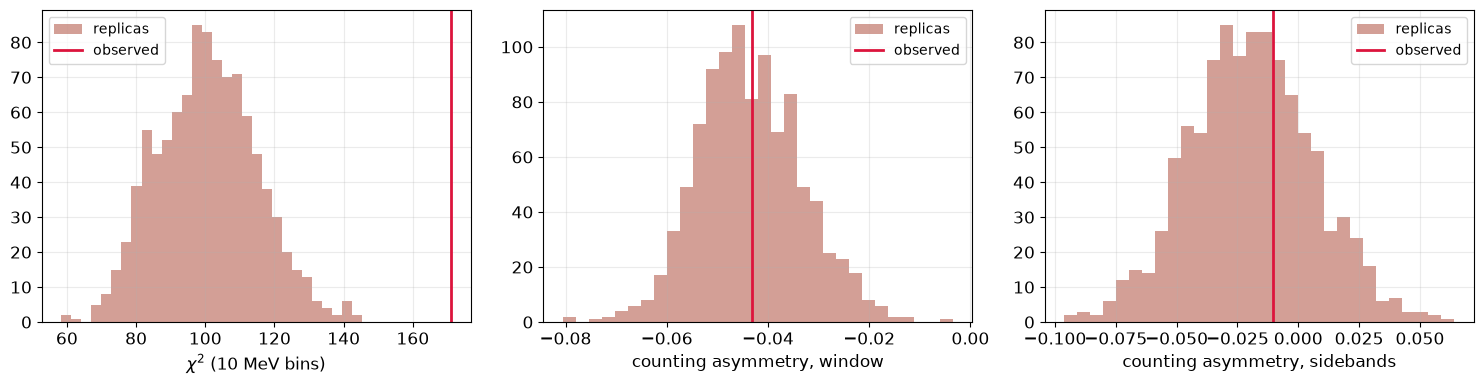

In [14]:
# posterior predictive check: distribution of each statistic in the replicas, and the observed value
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for k, (a, lab) in enumerate(zip(ax, ("$\\chi^2$ (10 MeV bins)", "counting asymmetry, window", "counting asymmetry, sidebands"))):
    a.hist(T_rep[:, k], bins=30, color=C["bayes"], alpha=0.5, label="replicas")
    a.axvline(np.median(T_obs[:, k]), color=C["model"], lw=2, label="observed")
    a.set(xlabel=lab); a.legend()
plt.tight_layout(); save_fig("06_posterior_predictive_check")
np.savez("results/06_ppc_statistics.npz", observed=T_obs, replicas=T_rep)

**Statistics that the fit does not adjust.** The binned $\chi^2$ is optimised (indirectly) by the fit, so it is a weak
test. Two statistics that it does not optimise:

* $T=\sum_s(A_s-\bar A_s)^2/\sigma_s^2$: the asymmetry in ten slices of 50 MeV of the mass against the one predicted by
  the model (a prediction, since the slice asymmetry varies only through the signal fraction);
* $D=\chi^2(B^+)-\chi^2(B^-)$: the difference between the goodness of fit of the two charges.

In [15]:
edges50 = np.arange(LO, HI + 1e-9, 50.0)                               # ten slices of 50 MeV
pts50 = edges50[:-1, None] + ((np.arange(10) + 0.5) / 10)[None, :] * 50.0

def expected_counts(v, side, pts, width):
    """Expected number of events per bin of one charge, from the parameter dictionary v."""
    sign = -1 if side == "pos" else +1
    dens = ((v["N_s"] * (1 + sign * v["A"]) / 2) * gauss_pdf(pts, v["mu"], v["sigma"])
            + (v["N_b"] * (1 + sign * v["A_b"]) / 2) * bkg_pdf(pts, v[f"lam1_{side}"], v[f"lam2_{side}"], v[f"f_{side}"]))
    return dens.mean(axis=1) * width

def stat_T(m_p, m_n, v):
    """T = sum over slices of (A_obs - A_model)^2 / var: asymmetry per slice of the mass against the model prediction."""
    ep, en = expected_counts(v, "pos", pts50, 50.0), expected_counts(v, "neg", pts50, 50.0)
    a_exp = (en - ep) / (en + ep); var = (1 - a_exp**2) / (en + ep)       # predicted asymmetry and its variance
    n_p, n_n = np.histogram(m_p, edges50)[0], np.histogram(m_n, edges50)[0]
    return np.sum(((n_n - n_p) / np.maximum(n_n + n_p, 1) - a_exp)**2 / var)

def stat_D(m_p, m_n, v):
    """D = chi2(B+) - chi2(B-): difference between the goodness of fit of the two charges."""
    out = []
    for side, mm in (("pos", m_p), ("neg", m_n)):
        nu = expected_counts(v, side, pts10, 10.0)
        out.append(np.sum((np.histogram(mm, edges10)[0] - nu)**2 / nu))
    return out[0] - out[1]

# same procedure as above: observed statistic and replica statistic for each posterior draw
T_o, T_r, D_o, D_r = [], [], [], []
for i in np.random.choice(len(chain), 500, replace=False):
    v = dict(zip(names, chain[i]))
    mp_r, mn_r = make_toy(v)
    T_o.append(stat_T(m_pos, m_neg, v)); T_r.append(stat_T(mp_r, mn_r, v))
    D_o.append(stat_D(m_pos, m_neg, v)); D_r.append(stat_D(mp_r, mn_r, v))
T_o, T_r, D_o, D_r = map(np.array, (T_o, T_r, D_o, D_r))
p_T = np.mean(T_r >= T_o); p_D = 2 * min(np.mean(D_r >= D_o), np.mean(D_r <= D_o))     # D is two-sided
print(f"T (10 slices): observed {np.median(T_o):.1f}, replicas {T_r.mean():.1f} +- {T_r.std():.1f},  p_B = {p_T:.2f}   (report: 0.67)")
print(f"D = chi2(B+) - chi2(B-): observed {np.median(D_o):.1f}, replicas {D_r.mean():.1f} +- {D_r.std():.1f},  p_B = {p_D:.2f}   (report: 0.08)")

T (10 slices): observed 7.4, replicas 9.8 +- 4.4,  p_B = 0.62   (report: 0.67)
D = chi2(B+) - chi2(B-): observed 27.0, replicas 0.2 +- 13.8,  p_B = 0.06   (report: 0.08)


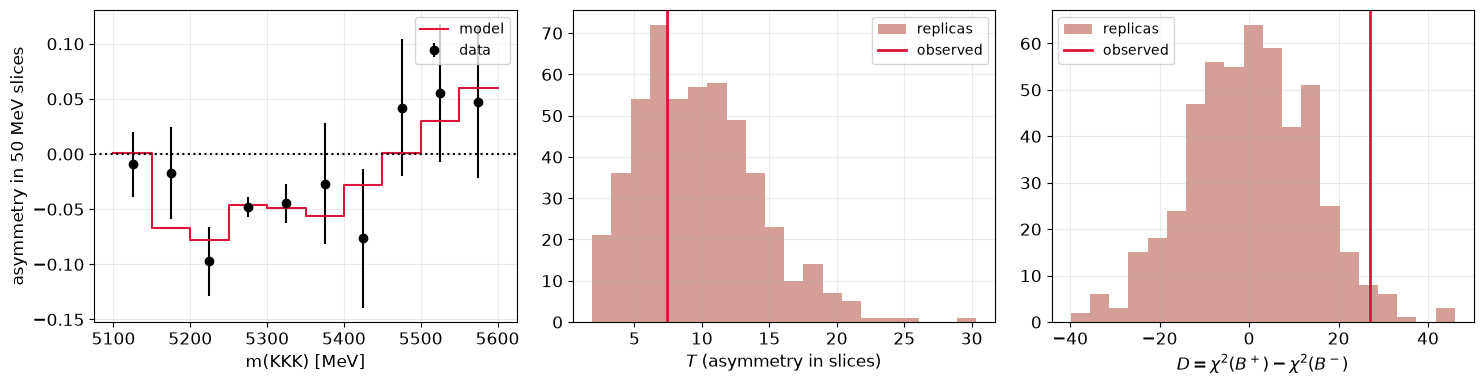

In [16]:
# the asymmetry in slices of the mass (data against the model) and the two statistics not fitted by the model
v_m = dict(zip(names, np.median(chain, axis=0)))
ep_, en_ = expected_counts(v_m, "pos", pts50, 50.0), expected_counts(v_m, "neg", pts50, 50.0)
n_p, n_n = np.histogram(m_pos, edges50)[0], np.histogram(m_neg, edges50)[0]
a_obs_s = (n_n - n_p) / (n_n + n_p)
a_err_s = np.sqrt((1 - a_obs_s**2) / (n_n + n_p))
cen50 = 0.5 * (edges50[1:] + edges50[:-1])
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].errorbar(cen50, a_obs_s, a_err_s, fmt="o", color="k", label="data")
ax[0].step(edges50, np.append((en_ - ep_) / (en_ + ep_), ((en_ - ep_) / (en_ + ep_))[-1]), where="post", color=C["model"], label="model")
ax[0].axhline(0, color="k", ls=":"); ax[0].set(xlabel="m(KKK) [MeV]", ylabel="asymmetry in 50 MeV slices"); ax[0].legend()
ax[1].hist(T_r, bins=20, color=C["bayes"], alpha=0.5, label="replicas"); ax[1].axvline(np.median(T_o), color=C["model"], lw=2, label="observed")
ax[1].set(xlabel="$T$ (asymmetry in slices)"); ax[1].legend()
ax[2].hist(D_r, bins=20, color=C["bayes"], alpha=0.5, label="replicas"); ax[2].axvline(np.median(D_o), color=C["model"], lw=2, label="observed")
ax[2].set(xlabel="$D=\\chi^2(B^+)-\\chi^2(B^-)$"); ax[2].legend()
plt.tight_layout(); save_fig("06_ppc_unfitted_statistics")
np.savez("results/06_ppc_unfitted.npz", T_obs=T_o, T_rep=T_r, D_obs=D_o, D_rep=D_r)

## 8 · Robustness: magnet polarities, Dalitz region and charm veto

**Magnet polarities and sequential update.** The two polarities are fitted separately. Bayesian learning is
*sequential*: the posterior of the first sample is the prior of the second, so the product of the two posteriors of $A$
(normalised) must reproduce the posterior of the joint fit if the two samples share the same $A$.

magnet down: n =  11636   A = -0.0499 +- 0.0110


magnet up  : n =   8095   A = -0.0378 +- 0.0133
report: down -0.0497 [-0.0607,-0.0386], up -0.0378 [-0.0507,-0.0251]; difference 0.7 sigma


sequential update (down x up): A = -0.0450 +- 0.0087;   joint fit: -0.0442 +- 0.0085


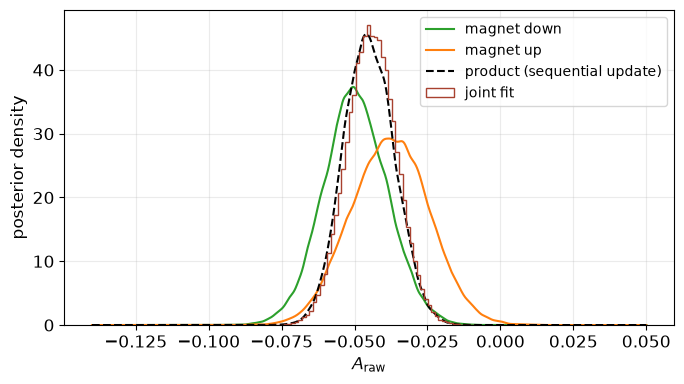

In [17]:
pol_res = {}
for pol in ("down", "up"):
    s = sample[sample.magnet == pol]
    pol_res[pol] = bayes_fit(s, nsteps=10000, burn=2000)          # posterior of A for each polarity
    print(f"magnet {pol:4s}: n = {len(s):6d}   A = {pol_res[pol]['A']:+.4f} +- {pol_res[pol]['sd']:.4f}")
print("report: down -0.0497 [-0.0607,-0.0386], up -0.0378 [-0.0507,-0.0251]; difference 0.7 sigma")

# sequential update: the posterior of "down" is the prior of "up", so the new posterior is the product of the two
xs = np.linspace(-0.14, 0.05, 2000)
dens = [gaussian_kde(pol_res[p]["chain"][:, pol_res[p]["names"].index("A")])(xs) for p in ("down", "up")]   # smooth the samples
post_seq = dens[0] * dens[1]
post_seq /= np.trapezoid(post_seq, xs)                          # normalise
mean_seq = np.trapezoid(xs * post_seq, xs); sd_seq = np.sqrt(np.trapezoid((xs - mean_seq)**2 * post_seq, xs))
print(f"sequential update (down x up): A = {mean_seq:+.4f} +- {sd_seq:.4f};   joint fit: {np.median(A_s):+.4f} +- {A_s.std():.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(xs, dens[0], color=C["down"], label="magnet down"); ax.plot(xs, dens[1], color=C["up"], label="magnet up")
ax.plot(xs, post_seq, "k--", label="product (sequential update)")
ax.hist(A_s, bins=60, density=True, histtype="step", color=C["bayes"], label="joint fit")
ax.set(xlabel="$A_{\\rm raw}$", ylabel="posterior density"); ax.legend(); plt.tight_layout(); save_fig("06_sequential_update")

In [18]:
pd.DataFrame([dict(polarity=p, n=int((sample.magnet == p).sum()), A=r["A"], sd=r["sd"], ci68_lo=r["ci68"][0], ci68_hi=r["ci68"][1])
              for p, r in pol_res.items()]).to_csv("results/06_polarities.csv", index=False)
np.savez("results/06_polarity_posteriors.npz", down=pol_res["down"]["chain"][:, pol_res["down"]["names"].index("A")],
         up=pol_res["up"]["chain"][:, pol_res["up"]["names"].index("A")])

**Dalitz region of the published analysis and charm veto.** The counting analysis of the Dalitz plane (maps,
homogeneity test, permutation) does not involve a likelihood and is the same for the two methods: it is in
notebook 04 (§9). Here we only do what needs the fit: the nominal Bayesian model on the candidates of the region
$1.2<m^2_{\rm lo}<2.0$ GeV$^2$, $m^2_{\rm hi}<15$ GeV$^2$ of the published analysis (a region fixed by the paper),
and on the sample without the $D^0$ resonance.

In [19]:
# squared masses (GeV^2) of the two opposite-sign pairs, sorted: m2_lo <= m2_hi
lo2 = (np.minimum(sample.m12, sample.m13) / 1e3)**2
hi2 = (np.maximum(sample.m12, sample.m13) / 1e3)**2
region = sample[((lo2 > 1.2) & (lo2 < 2.0) & (hi2 < 15)).to_numpy()]     # region of the published analysis
r_reg = bayes_fit(region, nsteps=10000, burn=2000)
print(f"Dalitz region: n = {len(region)} (report 2146);  A = {r_reg['A']:+.3f} +- {r_reg['sd']:.3f}     "
      f"(report: -0.234 +- 0.025; published: -0.239 +- 0.020)")

# D0 veto: remove candidates with an opposite-sign pair within 30 MeV of the D0 mass
keep = ~((np.abs(sample.m12 - 1864.84) < 30) | (np.abs(sample.m13 - 1864.84) < 30))
r_d0 = bayes_fit(sample[keep.to_numpy()], nsteps=10000, burn=2000)
print(f"D0 veto: n = {keep.sum()} (report 18744);  A = {r_d0['A']:+.4f} +- {r_d0['sd']:.4f}     (report: -0.0496 +- 0.0088)")

Dalitz region: n = 2146 (report 2146);  A = -0.236 +- 0.025     (report: -0.234 +- 0.025; published: -0.239 +- 0.020)


D0 veto: n = 18744 (report 18744);  A = -0.0487 +- 0.0088     (report: -0.0496 +- 0.0088)


## 9 · Comparison with the frequentist profile likelihood

With flat priors the posterior is proportional to the likelihood, so the two inferences should coincide
numerically while meaning different things. The profile likelihood is computed here with `Minuit` on the same
function ($-2\ln$ posterior; `mnprofile` re-minimises the 11 nuisance parameters at each $A$).

* **Frequentist**: profile the nuisance parameters; interval = set not rejected by the data, $q(A)\le1$.
* **Bayesian**: marginalise them; credible interval = region with 68 % posterior probability.

In [20]:
# frequentist side: the same function (-2 ln posterior) profiled with Minuit
mmap.hesse()
a_p, f_p, _ = mmap.mnprofile("A", size=30, bound=(-0.085, 0.0))      # re-minimise the 11 nuisance parameters at each A
q_p = f_p - mmap.fval                                                # q(A) = -2 ln L - minimum
like = np.exp(-0.5 * q_p); like /= np.trapezoid(like, a_p)           # exp(-q/2), normalised like a density
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(A_s, bins=60, range=(-0.085, 0), density=True, color=C["bayes"], alpha=0.4, label="Bayesian: marginal posterior")
ax[0].plot(a_p, like, color=C["freq"], lw=2, label="Frequentist: $\\exp[-q(A)/2]$, normalised")
ax[0].set(xlabel="$A_{\\rm raw}$", ylabel="density"); ax[0].legend()
# joint region of (A, A_b): profile-likelihood contours (chi2 with 2 d.o.f.) against Bayesian HPD regions
mmap.draw_mncontour("A", "A_b", cl=[0.683, 0.954], size=40)
plt.close()
cont68, cont95 = mmap.mncontour("A", "A_b", cl=0.683, size=40), mmap.mncontour("A", "A_b", cl=0.954, size=40)
H, xe, ye = np.histogram2d(A_s, Ab_s, bins=50, density=True)         # 2D posterior as a histogram of the chain
Hs = np.sort(H.ravel())[::-1]; cum = np.cumsum(Hs) * (xe[1] - xe[0]) * (ye[1] - ye[0])
levels = sorted([Hs[np.searchsorted(cum, p)] for p in (0.683, 0.954)])    # density levels enclosing 68 % and 95 %
ax[1].contour(0.5 * (xe[1:] + xe[:-1]), 0.5 * (ye[1:] + ye[:-1]), H.T, levels=levels, colors=C["bayes"])
for cnt, ls in ((cont68, "-"), (cont95, "--")):
    ax[1].plot(np.append(cnt[:, 0], cnt[0, 0]), np.append(cnt[:, 1], cnt[0, 1]), color=C["freq"], ls=ls)
ax[1].axvline(0, color="k", ls=":"); ax[1].axhline(0, color="k", ls=":")
ax[1].set(xlabel="$A$", ylabel="$A_b$", title="frequentist (teal) and Bayesian (red) 68 %/95 % regions")
plt.tight_layout(); save_fig("06_profile_vs_posterior")

print(f"Frequentist: A = {mmap.values['A']:+.4f} +- {mmap.errors['A']:.4f} (Hesse)    Bayesian: {np.median(A_s):+.4f} +- {A_s.std():.4f}")
print("the Hesse uncertainties and the posterior standard deviations of the other parameters:")
for k in ("A_b", "N_s", "N_b", "mu", "sigma"):
    print(f"  {k:6s} Hesse {mmap.errors[k]:9.4f}   posterior sd {chain[:, names.index(k)].std():9.4f}")

<Figure size 700x420 with 0 Axes>

Frequentist: A = -0.0441 +- 0.0085 (Hesse)    Bayesian: -0.0442 +- 0.0085
the Hesse uncertainties and the posterior standard deviations of the other parameters:
  A_b    Hesse    0.0176   posterior sd    0.0175
  N_s    Hesse  132.6427   posterior sd  131.6203
  N_b    Hesse   81.6658   posterior sd   81.7073
  mu     Hesse    0.1591   posterior sd    0.1606
  sigma  Hesse    0.1401   posterior sd    0.1404


**Reading the result.** The marginal posterior and the normalised $\exp(-q/2)$ coincide, and so do the 68 % and 95 % regions in $(A,A_b)$ with $A=0$ outside both: profiling and marginalising the nuisance parameters give the same answer because $A$ is almost uncorrelated with them.

## Results saved

In [21]:
summary = dict(
    posterior=dict(A_median=float(np.median(A_s)), sd=float(A_s.std())),
    systematics=dict(groups={k: float(v) for k, v in group_unc.items()}, total=float(syst_total)),
    toys=dict(coverage68=float(toys.in68.mean()), coverage95=float(toys.in95.mean()), pull_width=float(pull.std()), n=int(len(toys))),
    dalitz_region=dict(A=float(r_reg["A"]), sd=float(r_reg["sd"]), n=int(len(region))))
json.dump(summary, open("results/06_summary.json", "w"), indent=1)
syst.to_csv("results/06_systematics_variants.csv", index=False); toys.to_csv("results/06_toys.csv", index=False)
print("saved results/06_summary.json and the tables; figures in figures/")

saved results/06_summary.json and the tables; figures in figures/


## Summary
* The Bayesian systematic study gives shifts that agree variant by variant with the frequentist ones (preselection
  dominates); chains here are short, so the shifts close to the $\sigma_B$ threshold can be classified differently.
* The 68 % and 95 % credible intervals **cover** the true value on toys with the right frequency.
* The model does not reach $\chi^2/{\rm ndof}\approx1$, but the posterior predictive check reproduces the asymmetry in
  the window and in the sidebands and in slices of the mass.
* The two polarities agree and their sequential update reproduces the joint posterior; profile likelihood and
  posterior coincide, as do the regions in $(A,A_b)$.

In [22]:
print(f"Running time of this notebook: {(time.time() - T0) / 60:.1f} min")

Running time of this notebook: 85.9 min
